# Photon-distribution-aware discrete loss model

This notebook reproduces the first comparison figure from `break_even_gamma_ratio_alpha7.ipynb` for $d=m_i=16$ and adds opt-in `PhotonDistributionQudit` curves. The solid blue curve uses squeezing $\zeta=-0.8$ and the dashed blue curve uses $\zeta=0$. Each model uses the corresponding state's marginal photon-number distribution independently for both cavities. It improves loss-count probabilities only; it does not reproduce conditional-state deformation under the full loss Kraus action.

In [1]:
import io
import sys
from contextlib import redirect_stdout
from pathlib import Path

import dill
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from qutip import basis, coherent, displace, fidelity, squeeze, tensor

ROOT = Path.cwd()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from continuous import ContinuousProtocol
from discrete_simulation import DiscreteSimulation
from qudit import PhotonDistributionQudit, photon_number_distribution_from_state

PLOTS_DIR = ROOT / "plots"
RESULTS_DIR = ROOT / "results"
PLOTS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

In [2]:
d = 16
m_i = 16
m_c = 8
m_f = 2
alpha = 7
N = 200
squeezed = -0.8
ratio = 1

In [3]:
mpl.rcParams["text.usetex"] = False
mpl.rcParams["text.latex.preamble"] = r"\usepackage{amsmath}"
mpl.rcParams["font.family"] = "DejaVu Serif"
plt.style.use("bmh")
mpl.rcParams["axes.facecolor"] = "w"
plt.rcParams["font.size"] = 14
mpl.rc("xtick", labelsize=14)
mpl.rc("ytick", labelsize=14)

coherent_state = coherent(N, alpha)
protocol = ContinuousProtocol(coherent_state, res=d, m_i=m_i, m_c=m_c)
limit = (coherent_state.dag() * protocol._create_phase_parity_measurement(1) * coherent_state).full()[0][0].real
coherent_pre_loss_marginal = protocol._create_initial_state().ptrace(0)
coherent_photon_distribution = photon_number_distribution_from_state(coherent_pre_loss_marginal)

squeezed_state = displace(N, alpha) * squeeze(N, squeezed) * coherent(N, 0)
limit_sq = (squeezed_state.dag() * protocol._create_phase_parity_measurement(1) * squeezed_state).full()[0][0].real
squeezed_protocol = ContinuousProtocol(squeezed_state, res=d, m_i=m_i, m_c=m_c)
pre_loss_marginal = squeezed_protocol._create_initial_state().ptrace(0)
squeezed_photon_distribution = photon_number_distribution_from_state(pre_loss_marginal)
photon_numbers = np.arange(len(squeezed_photon_distribution))
photon_mean = np.sum(photon_numbers * squeezed_photon_distribution)
photon_std = np.sqrt(np.sum((photon_numbers - photon_mean) ** 2 * squeezed_photon_distribution))

def normalized_factorial_moment(order):
    falling_factorial = np.ones_like(photon_numbers, dtype=float)
    for offset in range(order):
        falling_factorial *= photon_numbers - offset
    return np.sum(falling_factorial * squeezed_photon_distribution) / photon_mean**order

factorial_moments = [normalized_factorial_moment(order) for order in range(1, 5)]
if not np.isclose(photon_std, 15.7, atol=0.1):
    raise RuntimeError(f"Squeezed-state convention mismatch: Delta n = {photon_std:.6f}")

print(f"n_bar = {photon_mean:.6f}")
print(f"Delta n = {photon_std:.6f}")
for order, moment in enumerate(factorial_moments, start=1):
    print(f"g_{order} = {moment:.6f}")

n_bar = 49.788732
Delta n = 15.669086
g_1 = 1.000000
g_2 = 1.078958
g_3 = 1.246243
g_4 = 1.531411


In [4]:
baseline_path = RESULTS_DIR / "break_even_alpha=7_gamma_l_over_gamma_phi=1.pkl"
with baseline_path.open("rb") as file:
    baseline = dill.load(file)

required_keys = {
    "gamma_loss_list",
    "fid_discrete",
    "fid_continuous",
    "fid_continuous_sq",
    "fid_discrete_minus",
    "fid_discrete_plus",
    "fid_discrete_minus_sq",
    "fid_discrete_plus_sq",
}
missing_keys = sorted(required_keys - set(baseline))
if missing_keys:
    raise ValueError(f"Baseline cache is incomplete; missing {missing_keys}")
if baseline.get("m_i", m_i) != m_i:
    raise ValueError(f"Baseline cache uses m_i={baseline['m_i']}, expected {m_i}")

def real_array(values):
    array = np.asarray(values)
    if np.any(np.abs(np.imag(array)) > 1e-10):
        raise ValueError("Expected real-valued cached results")
    return np.real(array).astype(float)

gamma_loss_list = real_array(baseline["gamma_loss_list"])
gamma_dephasing_list = gamma_loss_list / ratio

In [5]:
def run_improved_discrete(photon_distribution):
    simulation = DiscreteSimulation(
        d,
        m_i,
        m_c,
        m_f=m_f,
        alpha=alpha,
        qudit_class=PhotonDistributionQudit,
        qudit_kwargs={"photon_number_distribution": photon_distribution},
    )
    fidelity_values = []
    failure_probabilities = []
    for gamma_loss, gamma_dephasing in zip(gamma_loss_list, gamma_dephasing_list):
        with redirect_stdout(io.StringIO()):
            fidelity_value, failure_probability = simulation.average_fidelity(
                gamma_loss, gamma_dephasing
            )
        fidelity_values.append(fidelity_value)
        failure_probabilities.append(failure_probability)
    return np.asarray(fidelity_values), np.asarray(failure_probabilities)

improved_fidelity, improved_failure_probability = run_improved_discrete(
    squeezed_photon_distribution
)
improved_fidelity_squeezing_0, improved_failure_probability_squeezing_0 = (
    run_improved_discrete(coherent_photon_distribution)
)
improved_path = RESULTS_DIR / "break_even_alpha=7_gamma_l_over_gamma_phi=1_photon_improved.pkl"
with improved_path.open("wb") as file:
    dill.dump(
        {
            "d": d,
            "m_i": m_i,
            "m_c": m_c,
            "m_f": m_f,
            "alpha": alpha,
            "squeezed": squeezed,
            "gamma_loss_list": gamma_loss_list,
            "fid_photon_improved": improved_fidelity,
            "prob_photon_improved": improved_failure_probability,
            "fid_photon_improved_squeezing_0": improved_fidelity_squeezing_0,
            "prob_photon_improved_squeezing_0": improved_failure_probability_squeezing_0,
            "photon_mean": photon_mean,
            "photon_std": photon_std,
            "factorial_moments": factorial_moments,
        },
        file,
    )

In [6]:
original_infidelity = 1 - real_array(baseline["fid_discrete"])
improved_infidelity = 1 - improved_fidelity
improved_infidelity_squeezing_0 = 1 - improved_fidelity_squeezing_0
continuous_sq_infidelity = 1 - real_array(baseline["fid_continuous_sq"])
infidelity_change = improved_infidelity - original_infidelity
original_gap = np.abs(original_infidelity - continuous_sq_infidelity)
improved_gap = np.abs(improved_infidelity - continuous_sq_infidelity)
gap_closed = original_gap - improved_gap

print("gamma_l    original      improved      squeezed CV   improved-original   gap closed")
for index in (0, len(gamma_loss_list) // 2, len(gamma_loss_list) - 1):
    print(
        f"{gamma_loss_list[index]:.3e}  "
        f"{original_infidelity[index]:.6e}  "
        f"{improved_infidelity[index]:.6e}  "
        f"{continuous_sq_infidelity[index]:.6e}  "
        f"{infidelity_change[index]:+.6e}  "
        f"{gap_closed[index]:+.6e}"
    )
print(f"Improved curve is closer to squeezed CV at {np.count_nonzero(gap_closed > 0)}/{len(gap_closed)} points.")

gamma_l    original      improved      squeezed CV   improved-original   gap closed
1.000e-03  3.554392e-06  4.677326e-06  1.009053e-04  +1.122934e-06  +1.122934e-06
1.000e-02  6.527688e-02  6.842083e-02  8.390579e-02  +3.143949e-03  +3.143949e-03
1.000e-01  7.002228e-01  7.093943e-01  7.026799e-01  +9.171500e-03  -4.257282e-03
Improved curve is closer to squeezed CV at 14/15 points.


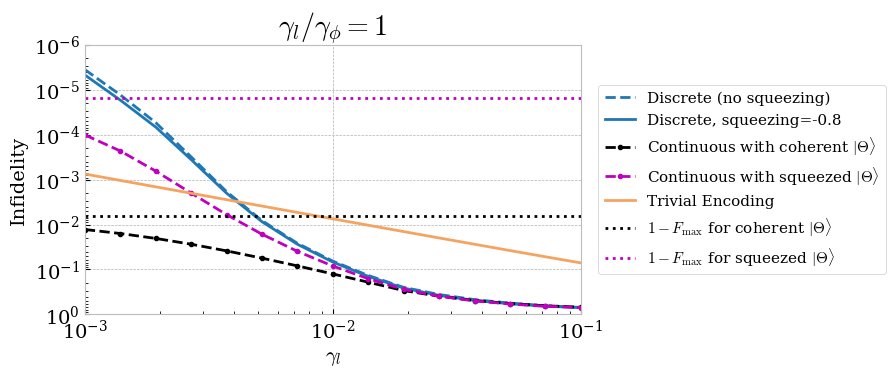

In [7]:
def plot_break_even(ax, data):
    gamma = gamma_loss_list
    # ax.loglog(gamma, 1 - real_array(data["fid_discrete"]), "g-", label="Discrete")
    ax.loglog(gamma, improved_infidelity_squeezing_0, color="tab:blue", linestyle="--", label="Discrete (no squeezing)")
    ax.loglog(gamma, improved_infidelity, color="tab:blue", label="Discrete, squeezing=-0.8")
    ax.loglog(gamma, 1 - real_array(data["fid_continuous"]), "k.--", label=r"Continuous with coherent $|\Theta\rangle$")
    ax.loglog(gamma, 1 - real_array(data["fid_continuous_sq"]), "m.--", label=r"Continuous with squeezed $|\Theta\rangle$")

    trivial_state = (tensor(basis(2, 0), basis(2, 0)) + tensor(basis(2, 1), basis(2, 1))).unit()
    trivial_helper = ContinuousProtocol(trivial_state, res=10, m_i=2, m_c=2)
    trivial_fidelity = np.asarray([
        fidelity(
            trivial_state,
            trivial_helper._add_noise(
                trivial_state, gamma_loss=g, gamma_dephasing=g / ratio, max_loss_level=10
            ).unit(),
        )
        for g in gamma
    ])
    ax.loglog(gamma, 1 - trivial_fidelity, color="sandybrown", label="Trivial Encoding")

    # ax.fill_between(
    #     gamma,
    #     1 - real_array(data["fid_discrete_minus"]),
    #     1 - real_array(data["fid_discrete_plus"]),
    #     color="g",
    #     alpha=0.3,
    # )
    # ax.fill_between(
    #     gamma,
    #     1 - real_array(data["fid_discrete_minus_sq"]),
    #     1 - real_array(data["fid_discrete_plus_sq"]),
    #     color="g",
    #     alpha=0.3,
    # )
    ax.axhline(limit, color="k", linestyle=":", label=r"$1-F_{\mathrm{max}}$ for coherent $|\Theta\rangle$")
    ax.axhline(limit_sq, color="m", linestyle=":", label=r"$1-F_{\mathrm{max}}$ for squeezed $|\Theta\rangle$")
    ax.set_xlabel(r"$\gamma_l$", fontsize=15)
    ax.set_ylabel("Infidelity", fontsize=14)
    ax.set_ylim([1, 1e-6])
    ax.set_xlim([gamma.min(), gamma.max()])
    ax.grid(linestyle="--", linewidth=0.5)
    ax.set_title(r"$\gamma_l/\gamma_\phi=1$")
    ax.legend(
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        prop={"size": 11},
        framealpha=1,
    )

fig, ax = plt.subplots(dpi=100, figsize=(6.4, 3.5))
plot_break_even(ax, baseline)
figure_stem = "continuous_vs_discrete_alpha=7_gamma_l_over_gamma_phi=1_photon_improved"
fig.savefig(PLOTS_DIR / f"{figure_stem}.svg", bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"{figure_stem}.pdf", bbox_inches="tight")
plt.show()

In [8]:
appendix_paths = {
    0.1: RESULTS_DIR / (
        "break_even_alpha=7_gamma_l_over_gamma_phi=0p1_"
        "gamma_l=1em04_1em02_points=15.pkl"
    ),
    10: RESULTS_DIR / "break_even_alpha=7_gamma_l_over_gamma_phi=10.pkl",
}
appendix_gamma_loss = {
    0.1: np.logspace(-4, -2, 15),
    10: np.logspace(-3, -1, 15),
}

def run_improved_discrete_for_ratio(photon_distribution, gamma_loss, gamma_dephasing):
    simulation = DiscreteSimulation(
        d,
        m_i,
        m_c,
        m_f=m_f,
        alpha=alpha,
        qudit_class=PhotonDistributionQudit,
        qudit_kwargs={"photon_number_distribution": photon_distribution},
    )
    fidelity_values = []
    for gamma_l, gamma_phi in zip(gamma_loss, gamma_dephasing):
        with redirect_stdout(io.StringIO()), np.errstate(invalid="ignore"):
            fidelity_value, _ = simulation.average_fidelity(gamma_l, gamma_phi)
        fidelity_values.append(fidelity_value)
    return np.asarray(fidelity_values)

appendix_data = {}
appendix_improved = {}
for appendix_ratio, path in appendix_paths.items():
    if path.exists():
        with path.open("rb") as file:
            data = dill.load(file)
    else:
        data = {}
    gamma_loss = appendix_gamma_loss[appendix_ratio]
    if "gamma_loss_list" in data:
        np.testing.assert_allclose(data["gamma_loss_list"], gamma_loss)
    gamma_dephasing = gamma_loss / appendix_ratio
    appendix_data[appendix_ratio] = data
    appendix_improved[appendix_ratio] = {
        "gamma_loss_list": gamma_loss,
        "fid_squeezing_0": run_improved_discrete_for_ratio(
            coherent_photon_distribution, gamma_loss, gamma_dephasing
        ),
        "fid_squeezing_minus_0p8": run_improved_discrete_for_ratio(
            squeezed_photon_distribution, gamma_loss, gamma_dephasing
        ),
    }

appendix_improved_path = (
    RESULTS_DIR / "break_even_alpha=7_gamma_l_over_gamma_phi=0p1_10_photon_improved.pkl"
)
with appendix_improved_path.open("wb") as file:
    dill.dump(appendix_improved, file)

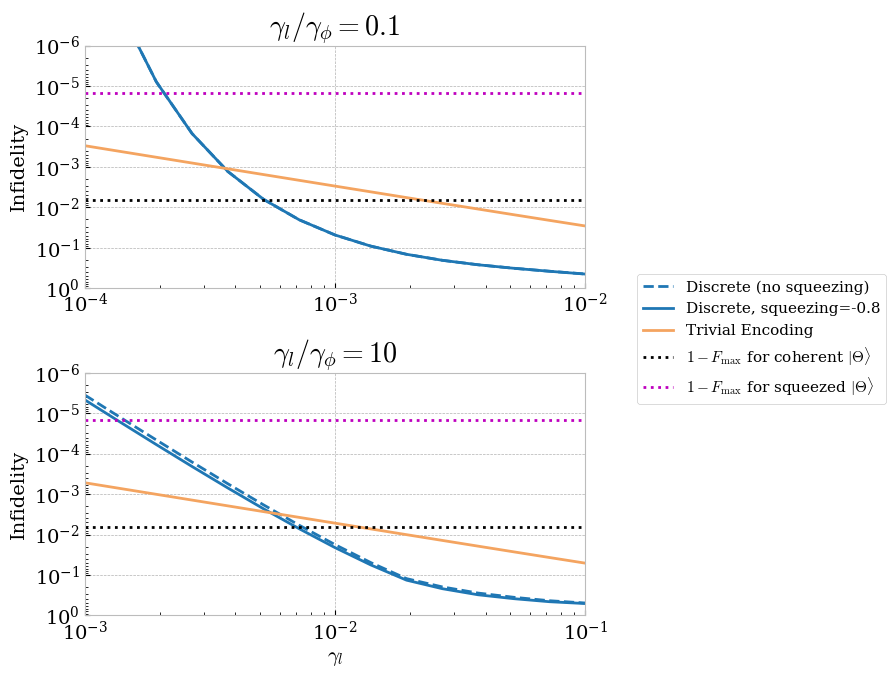

In [9]:
def plot_appendix_ratio(ax, data, improved, appendix_ratio):
    gamma = improved["gamma_loss_list"]
    ax.loglog(
        gamma,
        1 - improved["fid_squeezing_0"],
        color="tab:blue",
        linestyle="--",
        label="Discrete (no squeezing)",
    )
    ax.loglog(
        gamma,
        1 - improved["fid_squeezing_minus_0p8"],
        color="tab:blue",
        label="Discrete, squeezing=-0.8",
    )
    if "fid_continuous" in data:
        ax.loglog(
            gamma,
            1 - real_array(data["fid_continuous"]),
            "k.--",
            label=r"Continuous with coherent $|\Theta\rangle$",
        )
    if "fid_continuous_sq" in data:
        ax.loglog(
            gamma,
            1 - real_array(data["fid_continuous_sq"]),
            "m.--",
            label=r"Continuous with squeezed $|\Theta\rangle$",
        )

    trivial_state = (
        tensor(basis(2, 0), basis(2, 0))
        + tensor(basis(2, 1), basis(2, 1))
    ).unit()
    trivial_helper = ContinuousProtocol(trivial_state, res=10, m_i=2, m_c=2)
    trivial_fidelity = np.asarray([
        fidelity(
            trivial_state,
            trivial_helper._add_noise(
                trivial_state,
                gamma_loss=gamma_l,
                gamma_dephasing=gamma_l / appendix_ratio,
                max_loss_level=10,
            ).unit(),
        )
        for gamma_l in gamma
    ])
    ax.loglog(
        gamma,
        1 - trivial_fidelity,
        color="sandybrown",
        label="Trivial Encoding",
    )
    ax.axhline(
        limit,
        color="k",
        linestyle=":",
        label=r"$1-F_{\mathrm{max}}$ for coherent $|\Theta\rangle$",
    )
    ax.axhline(
        limit_sq,
        color="m",
        linestyle=":",
        label=r"$1-F_{\mathrm{max}}$ for squeezed $|\Theta\rangle$",
    )
    ax.set_ylabel("Infidelity", fontsize=14)
    ax.set_ylim([1, 1e-6])
    ax.set_xlim([gamma.min(), gamma.max()])
    ax.grid(linestyle="--", linewidth=0.5)
    ax.set_title(rf"$\gamma_l/\gamma_\phi={appendix_ratio:g}$")

fig, axs = plt.subplots(2, 1, dpi=100, figsize=(6.4, 7.0))
for ax, appendix_ratio in zip(axs, appendix_paths):
    plot_appendix_ratio(
        ax,
        appendix_data[appendix_ratio],
        appendix_improved[appendix_ratio],
        appendix_ratio,
    )
axs[-1].set_xlabel(r"$\gamma_l$", fontsize=15)
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    prop={"size": 11},
    framealpha=1,
)
fig.tight_layout()
appendix_stem = (
    "appendix_continuous_vs_discrete_alpha=7_"
    "gamma_l_over_gamma_phi=0p1_10_photon_improved"
)
fig.savefig(PLOTS_DIR / f"{appendix_stem}.svg", bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"{appendix_stem}.pdf", bbox_inches="tight")
plt.show()